In [2]:
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

In [ ]:
def get_spiral_data(
    theta_max, #accepts array as well
    points_per_spiral=250, 
    spirals_number=4, 
    max_noise=0,
    normalization=True, 
    seed=None,
    channels=100, #number of channels in the MZI-Mesh, standard-size stays 100
    padding="", #switch to control if we want to have a repeating vector like (e^(ix), e^(iy), e^(ix), e^(iy), e^(ix), ...) or (e^(ix), 0, e^(iy), 0, e^(ix), 0, e^(iy), 0, e^(ix), ...)
    theta_enc=1, #for encoding e^(itheta_enc*x)
    normalize_energy=False, 

    balanced=True,
    split_ratio=0.8,
    verbose=True,
    encoding="amplitude",
):
    """Load, sample, split and encode spiral data.

    Parameters
    ----------
    Returns Dataset(s) Training / Test-Set of the corresponding spirals
    -------
    E_train, y_train, E_test, y_test
    Fields as (N, B) complex, labels as (B,).
    """
    def generate_multiple_spirals(theta_max, points_per_spiral=250, spirals_number=4, max_noise=0,
              normalization=True):
        """ Generates the spirales of """
        #return a * np.exp(b * t) * np.array([np.cos(t), np.sin(t)])
        step = theta_max*np.pi/points_per_spiral
        t = np.linspace(step, theta_max*np.pi, points_per_spiral)

        Spirals = []
        if normalization:
            for i in range(0, spirals_number):
                Spirals.append((t / (theta_max * np.pi)) * np.array([np.cos(t + i * 2 * np.pi / spirals_number),
                                                                    np.sin(t + i * 2 * np.pi / spirals_number)])
                            + np.random.uniform(-max_noise / (theta_max * np.pi), max_noise / (theta_max * np.pi),
                                                points_per_spiral))
        else:
            for i in range(0, spirals_number):
                Spirals.append(
                    t * np.array([np.cos(t + i * 2 * np.pi / spirals_number), np.sin(t + i * 2 * np.pi / spirals_number)])
                    + np.random.uniform(-max_noise, max_noise, points_per_spiral))

        spirals_data = []
        for index, spiral_i in enumerate(Spirals):
            # combined_array = np.column_stack(((index+1)*np.ones(len(spiral_i[0])), spiral_i[0].flatten(),
            #                                   spiral_i[1].flatten()))
            combined_array = np.column_stack(((index)*np.ones(len(spiral_i[0])), spiral_i[0].flatten(),
                                            spiral_i[1].flatten()))
            spirals_data.append(combined_array)
        all_labels_coordinates = np.vstack([combined_array_i for combined_array_i in spirals_data])

        return all_labels_coordinates

    def prepare_data(data, test_size=0.2):
        # Extract X and y from the data
        XYs = data[:, 1:3]  # last two columns are x, y coordinates
        labels = data[:, 0].astype(int)  # first column is the label
        # Split the data into training and testing
        u_train, u_test, y_train, y_test = train_test_split(XYs, labels, test_size=test_size, random_state=90)
        # Convert labels to one-hot encoding
        y_train = to_categorical(y_train)
        y_test = to_categorical(y_test)
        return u_train, u_test, y_train, y_test

    values = generate_multiple_spirals(saving_dir, theta_max, points_per_spiral=250, spirals_number=4, max_noise=0,
              normalization=True)  # discard spiral_data
              
    rng = np.random.default_rng(seed)

    # shuffle the whole pool once
    perm = rng.permutation(len(y_all))
    X_all, y_all = X_all[perm], y_all[perm]

    # keep `number` samples, balanced if requested
    keep = _balanced_indices(y_all, values, number) if balanced else np.arange(len(y_all))[:number]
    X_all, y_all = X_all[keep], y_all[keep]

    # split into training and testing, both balanced per class
    X_train, y_train, X_test, y_test = split(X_all, y_all, values, split_ratio, rng)

    # encode ONLY the selected images
    E_train = encode_batch(X_train, m_side, theta_enc, normalize_energy, encoding_type=encoding).T
    E_test = encode_batch(X_test, m_side, theta_enc, normalize_energy, encoding_type=encoding).T

    if verbose:
        for name, y in (("Train", y_train), ("Test ", y_test)):
            counts = {int(v): int(np.sum(y == v)) for v in values}
            print(f"{name}: {len(y):5d} samples, class counts {counts}")
    return E_train, y_train, E_test, y_test






theta_maxes = [0.5, 1, 2, 4, 6]  # 0.5pi, 1pi, 2pi ... etc
number_of_spirals = 4
points_per_spirals = 250    # 200 to train per spiral and 50 to test
spiral_data = generate_multiple_spirals(theta_max,
                                        points_per_spiral=points_per_spirals,
                                        spirals_number=number_of_spirals, max_noise=0, normalization=True)

U_train, U_test, y_train, y_test = prepare_data(spiral_data)

import matplotlib.pyplot as plt
plt.plot(U_train)

NameError: name 'generate_multiple_spirals' is not defined

In [17]:
import numpy as np
import matplotlib.pyplot as plt


def plot_spirals(data, labels=None, ax=None, title=None, marker="o", s=20,
                 alpha=0.8, label_prefix="Spiral", show_legend=True):
    """Scatter plot of a spiral dataset, for checking/debugging the data.

    data   : (n, 3) array [label, x, y]  -- output of generate_multiple_spirals
             or (n, 2) array [x, y]       -- e.g. u_train / u_test
    labels : only used for (n, 2) data. Integer labels (n,) or one-hot (n, k),
             e.g. y_train / y_test. None -> all points in one colour.
    ax     : existing axes to draw into, e.g. to overlay train and test.
             None -> a new figure is created.
    marker : marker style, useful to distinguish train ("o") and test ("x").

    Returns (fig, ax).
    """
    data = np.asarray(data)
    if data.ndim != 2 or data.shape[1] not in (2, 3):
        raise ValueError(f"expected (n, 2) or (n, 3) array, got {data.shape}")

    # ---------- separate coordinates and labels ----------
    if data.shape[1] == 3:
        xy, lab = data[:, 1:3], data[:, 0].astype(int)
    else:
        xy = data
        if labels is None:
            lab = np.zeros(len(xy), dtype=int)       # single spiral / unlabelled
        else:
            labels = np.asarray(labels)
            lab = labels.argmax(axis=1) if labels.ndim == 2 else labels.astype(int)
        if len(lab) != len(xy):
            raise ValueError(f"{len(lab)} labels but {len(xy)} points")

    # ---------- plot ----------
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7))
    else:
        fig = ax.figure

    classes = np.unique(lab)
    cmap = plt.get_cmap("tab10")
    for c in classes:
        m = lab == c
        ax.scatter(xy[m, 0], xy[m, 1], s=s, alpha=alpha, marker=marker,
                   color=cmap(int(c) % 10), label=f"{label_prefix} {int(c) + 1}")

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    ax.set_title(title or f"{len(classes)} spiral(s), {len(xy)} points")
    if show_legend:
        ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5))
    return fig, ax

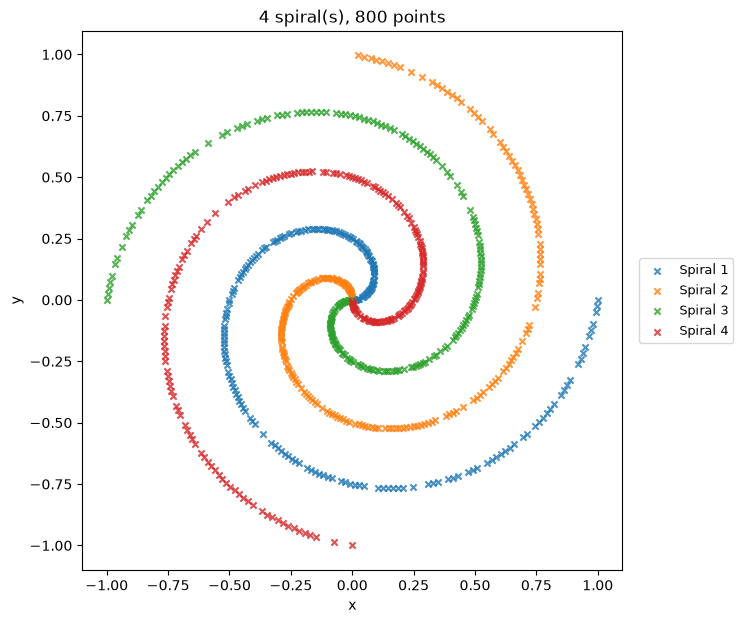

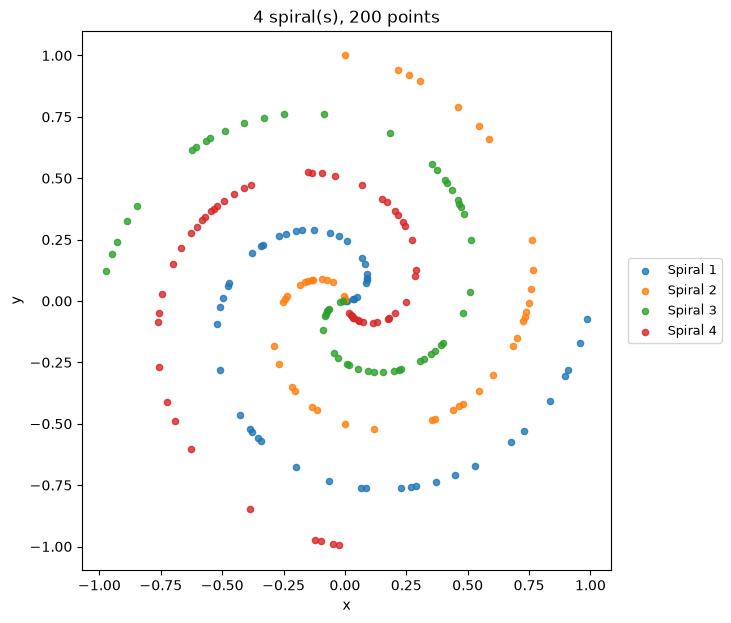

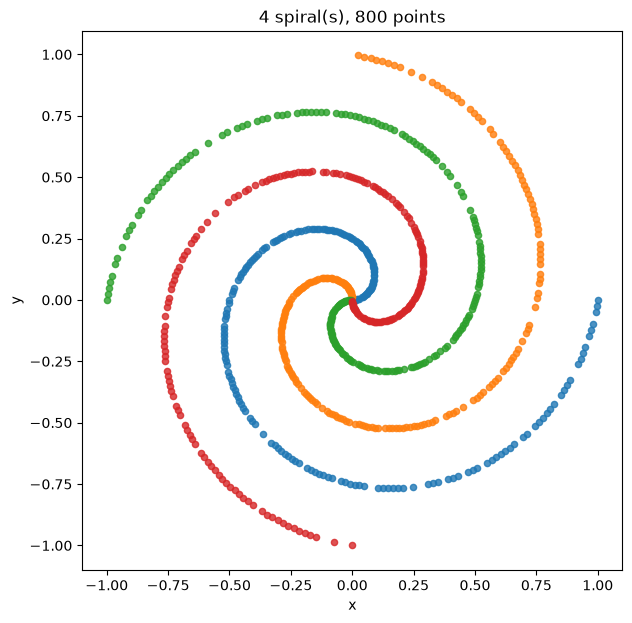

: 

In [ ]:
ax1 = plot_spirals(U_train, y_train, marker="x")
ax2 = plot_spirals(U_test, y_test)

fig, ax = plot_spirals(U_train, y_train, show_legend=False, label_prefix="Training")
#plot_spirals(U_test, y_test, ax=ax, marker="x", s=40, label_prefix="test")
